# Can a local language model fix the formatting?

Qwen3 hears the words best of the seven speech models, but its punctuation is among the
worst, so on the verbatim rule - where every comma, capital and dash counts - it loses to
Whisper. This notebook asks whether a language model running on the laptop can fix that,
and how far it can go before it starts changing what was said.

**How.** Gemma 4 31B, run locally through Ollama, was given every machine transcript in
chunks of about 400 words, three times over, with a prompt that allowed a little more
each time:

| step | the prompt allowed |
|---|---|
| 1 | punctuation, capitals, dashes, numbers as digits. **The words were locked**: anything else the model changed was put back in code |
| 2 | step 1, plus removing doubled words and fixing obvious mishearings |
| 3 | a conservative proofread toward a final transcript, shown real before/after examples |

Each step started from the machine's own words. The prompt examples came from 2010
arguments, never from the cases being scored. The 15 arguments - every fourth of the 61 -
were picked before anything was run. The tool is `../tools/llm_format.py` and the prompts
are in `../tools/llm_format_prompts/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

FOLDER = Path("..") / "findings" / "llm-format"
summary = pd.read_csv(FOLDER / "summary-gemma4-31b-sample.csv")
changes = pd.read_csv(FOLDER / "changes-gemma4-31b-sample.csv")
broken = pd.read_csv(FOLDER / "broken-words-gemma4-31b-sample.csv")
punctuation = pd.read_csv(FOLDER / "punctuation-gemma4-31b-sample.csv")

MODELS = ["Qwen3", "Whisper", "Voxtral", "Canary", "Granite", "Parakeet", "Granite Plus"]
STEP_NAMES = {0: "raw", 1: "1 format", 2: "2 light fixes", 3: "3 proofread"}

## 1. Verbatim error rate at each step

Lower is better. Each figure is the mean over the 15 arguments, scored exactly as the
published results are (step 0 reproduces them to within rounding).

In [2]:
verbatim = summary[summary["rule"] == "verbatim"].pivot(index="model", columns="step", values="wer")
verbatim = verbatim.loc[MODELS].rename(columns=STEP_NAMES)
verbatim.round(2)

step,raw,1 format,2 light fixes,3 proofread
model,,,,
Qwen3,15.70,13.48,14.78,13.79
Whisper,14.70,13.92,13.44,13.47
Voxtral,15.67,14.40,14.24,14.09
Canary,16.34,15.36,15.28,15.26
Granite,17.47,16.84,16.73,16.61
Parakeet,18.51,17.50,17.78,16.91
Granite Plus,29.28,17.43,17.46,16.46


**Formatting alone helps every model.** Step 1 cannot change a single word, and still
takes Qwen3 from 15.70% to 13.48% - past raw Whisper (14.70%) and past Whisper with the
same formatting (13.92%). Granite Plus, which writes no punctuation at all, drops from
29.28% to 17.43%.

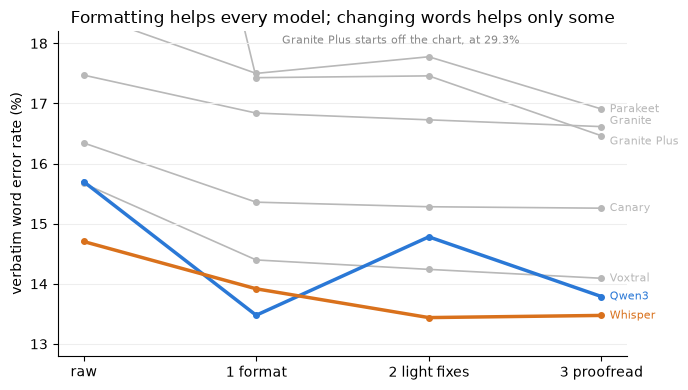

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
steps = list(STEP_NAMES.values())
for model in MODELS:
    values = verbatim.loc[model, steps].values
    if model == "Qwen3":
        style = {"color": "#2a78d6", "linewidth": 2.5, "zorder": 3}
    elif model == "Whisper":
        style = {"color": "#d9711c", "linewidth": 2.5, "zorder": 3}
    else:
        style = {"color": "#b8b8b8", "linewidth": 1.2, "zorder": 1}
    ax.plot(steps, values, marker="o", markersize=4, **style)
    nudge = {"Granite": 4, "Granite Plus": -4}.get(model, 0)
    ax.annotate(model, (3, values[-1]), xytext=(6, nudge), textcoords="offset points",
                va="center", fontsize=8, color=style["color"])

ax.set_ylim(12.8, 18.2)
ax.annotate("Granite Plus starts off the chart, at 29.3%", (1.15, 18.05), fontsize=8,
            color="#888888", va="center")
ax.set_ylabel("verbatim word error rate (%)")
ax.set_title("Formatting helps every model; changing words helps only some")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#eeeeee")
plt.tight_layout()
plt.show()

**After step 1 the line goes two ways.** For Whisper, Voxtral, Canary and Granite, steps 2
and 3 help a little more. For Qwen3, Parakeet and Granite Plus they make things worse. The
best two results are a tie: Qwen3 formatted only (13.48%) and Whisper with light fixes
(13.44%).

## 2. What the steps that may change words actually change

Each official word is checked before and after: **fixed** means wrong before and right
after, **broken** means right before and wrong after. Step 1 is compared with the raw
words, and steps 2 and 3 with step 1, so the counts show what allowing word changes added.

In [4]:
table = changes.groupby(["model", "step"])[["fixed", "broken"]].sum().unstack("step")
table.loc[MODELS]

fixed            broken            
step             1    2     3      1     2     3
model                                           
Qwen3          144  232   412     71  2285  1410
Whisper         46  275   396     36   198   361
Voxtral         65  206   363     23   119   340
Canary          75  500   763     60   379   671
Granite         30  297   484     10   217   449
Parakeet        51  488   760     38  1350  1667
Granite Plus   204  833  1125     99  2146  1751

Step 1's small counts are not real word changes - the words are locked. They come from the
scoring normaliser, which reads "1610(g)" and "sixteen ten g" differently.

For Qwen3, step 2 broke ten times as many words as it fixed. Most of them are repetitions:

In [5]:
qwen_step2 = broken[(broken["model"] == "Qwen3") & (broken["step"] == 2)]
qwen_step2[["official", "word", "llm_wrote"]].head(8)

,official,word,llm_wrote
4,deals particularly with what what i think is the,what,(nothing)
5,a thorough chance to to prove his compliance with,to,(nothing)
6,the con there is there is a possibility of,there,(nothing)
7,con there is there is a possibility of parole,is,(nothing)
8,screening and dhs is adequate is able adequate...,adequate,(nothing)
9,and dhs is adequate is able adequately to verify,is,(nothing)
10,keep statistics as to to the numbers i do,to,(nothing)
11,determination of eligibility for for asylum we...,for,(nothing)


"for for for years" in the record is "for -- for -- for years". The court reporter writes
down a speaker's restarts rather than tidying them away, so a prompt that removes doubled
words removes what the record keeps. Qwen3 writes these repetitions down; Whisper mostly
doesn't, so it has less to lose. Whisper instead has stray single words at the ends of its
segments ("Go.", "Heard.") that never appear in the record, and steps 2 and 3 cut the
words Whisper added from 1,092 to about 650. That is why the same prompt helps one model
and hurts the other.

## 3. Where the formatting gain comes from

For words both texts share, does the machine put the same mark after the word as the
record does? The table gives the F1 score for each mark (1.0 would match the record
exactly), before and after step 1.

In [6]:
punctuation["f1"] = 2 * punctuation["tp"] / (2 * punctuation["tp"] + punctuation["fp"] + punctuation["fn"])
marks = punctuation[punctuation["step"].isin([0, 1])].pivot_table(
    index="model", columns=["mark", "step"], values="f1")
marks.loc[MODELS, ["--", ","]].round(2)

mark           --           ,      
step            0     1     0     1
model                              
Qwen3         0.0  0.61  0.67  0.73
Whisper       0.0  0.27  0.79  0.80
Voxtral       0.0  0.11  0.72  0.79
Canary        0.0  0.27  0.74  0.76
Granite       0.0  0.13  0.74  0.75
Parakeet      0.0  0.50  0.72  0.75
Granite Plus  0.0  0.63  0.00  0.70

No speech model writes the reporter's "--" dash, which marks a restart or an interruption
and appears hundreds of times in every argument. After step 1, Qwen3 matches about 60% of
them. Commas improve a little. Whisper, Voxtral and Canary place far fewer dashes, because
they have already dropped most of the restarts a dash would go between.

## 4. What this means, and its limits

- **Much of the gap between hearing and the record is formatting, and a local model can
  close a good part of it without touching a word.** Each model's formatting penalty -
  verbatim minus the words-only rule - shrinks to between about 7.7 and 9.4 points.
- **What is left is out of reach of text alone.** Where a comma or a dash goes often
  depends on how something sounded.
- **Where the line falls depends on the recogniser.** Light fixes help a model that writes
  tidy text with stray junk words, and hurt one that writes down what was said. For the
  model that hears best, the right instruction is the strictest: format, and change
  nothing.
- **Limits.** 15 arguments is a sample. The prompt examples come from 2010, and the house
  style changed since (2010 writes "v.", 2017 "versus"). Gemma may have read Supreme Court
  transcripts in training. This is a two-step pipeline - speech model plus formatter -
  reported beside the plain scores, not instead of them.